### Importing relevant libraries

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import ttest_ind, chi2_contingency
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline 
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer 
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier 
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

pd.set_option("display.max_columns", None)

#### Columns to drop because they contain PII
    - candidate_id, full_name, email, phone, github_profile, linkedin_profile

#### selected is the Target column(Values: Selected/Rejected)

### Loading the dataset

In [3]:
resume_df = pd.read_csv("/kaggle/input/datasets/mobeenfatimah/resume-screening-and-ats-hiring-dataset100k-record/ai_resume_screening_dataset.csv")

resume_df.head()

,candidate_id,full_name,email,phone,country,city,age,gender,highest_education,university,field_of_study,cgpa,graduation_year,experience_years,previous_companies,current_job_title,internship_experience,leadership_experience,technical_skills,programming_languages,frameworks,databases,cloud_platform,projects_completed,github_profile,linkedin_profile,certifications,publications,communication_score,problem_solving_score,technical_test_score,interview_score,aptitude_score,job_role,expected_salary,preferred_location,employment_type,remote_preference,availability,resume_quality_score,resume_length,keyword_match_percentage,ats_score,selected
0,CAND-000001,Allison Hill,allison.hill13@gmail.com,+1-959-381-5012,Burundi,Lake Joyside,35,Female,Master,Georgia Institute of Technology,Mathematics & Statistics,2.63,2011,14,Not Applicable,Software Engineer,No,No,"Scikit-learn, HTML, Git",Not Applicable,Scikit-learn,Not Applicable,Not Applicable,7,https://github.com/allison.hill_325,https://linkedin.com/in/allison.hill-8359,Project Management Professional (PMP),0,77,70,78,92,67,Software Engineer,172000,Burundi,Internship,Hybrid,30 Days,72,2,20.00,46,Selected
1,CAND-000002,Javier Johnson,javier.johnson58@gmail.com,+1-299-467-6635,Djibouti,New Jamesside,37,Male,Master,National University of Singapore,Software Engineering,3.96,2008,17,Not Applicable,Cloud Engineer,No,Yes,"Pandas, HTML, Git, C++, Java, Kubernetes, CSS,...","C++, Java",Angular,Not Applicable,Kubernetes,5,https://github.com/javier.johns_564,https://linkedin.com/in/javier.johns-6977,"Microsoft Certified: Azure Fundamentals, AWS C...",0,81,65,76,63,64,Cloud Engineer,212000,Djibouti,Contract,Remote,Immediate,77,2,20.68,46,Rejected
2,CAND-000003,Jerry Ramirez,jerry.ramirez58@gmail.com,+1-476-755-4598,Senegal,Lake Roberto,41,Male,Bachelor,Massachusetts Institute of Technology,Artificial Intelligence,3.10,2005,21,Tesla,Mobile App Developer,Yes,No,"Express, PostgreSQL, Docker, Django, TypeScrip...",TypeScript,"Express, Django, React, Scikit-learn",PostgreSQL,"Docker, GCP",10,https://github.com/jerry.ramire_538,https://linkedin.com/in/jerry.ramire-7543,Not Applicable,0,44,64,51,74,59,Mobile App Developer,193000,Flexible,Full-Time,On-site,Immediate,58,2,62.55,65,Selected
3,CAND-000004,Daniel Gallagher,daniel.gallagher18@gmail.com,+1-594-490-8668,Bermuda,Davisstad,54,Male,PhD,Imperial College London,Computer Science,3.52,1994,32,"Palantir, Intel, Salesforce, Apple, Cisco",Full Stack Developer,No,No,"PyTorch, AWS, SQL, Redis, JavaScript, Docker, ...",JavaScript,"PyTorch, Angular","SQL, Redis","AWS, Docker",3,https://github.com/daniel.galla_482,https://linkedin.com/in/daniel.galla-3646,"Project Management Professional (PMP), Microso...",0,66,72,45,61,72,Full Stack Developer,351000,Davisstad,Contract,Hybrid,Immediate,61,1,28.58,43,Selected
4,CAND-000005,Robert Blair,robert.blair40@hotmail.com,+1-780-180-2403,British Virgin Islands,Millerport,52,Male,PhD,National University of Singapore,Data Science,2.69,1993,32,"Netflix, Intel, Databricks, Airbnb",AI Engineer,Yes,Yes,"Git, Angular, Express, Kubernetes, Docker, Nod...",Not Applicable,"Angular, Express, Node.js",Not Applicable,"Kubernetes, Docker",8,https://github.com/robert.blair_223,https://linkedin.com/in/robert.blair-5061,Project Management Professional (PMP),0,60,67,58,97,70,AI Engineer,374000,Millerport,Part-Time,Remote,15 Days,62,1,20.00,46,Selected


### Checking data quality

In [4]:
def basic_checks(df):
    print("-"*30, "Dataset Shape", "-"*30)
    print(df.shape)

    print("-"*30, "Missing Values", "-"*30)
    print(df.isnull().sum())

    print("-"*30, "Duplicates", "-"*30)
    print(df.duplicated().sum())

    print("-"*30, "Dataset Information", "-"*30)
    print(df.info())

    print("-"*30, "Statistical summary(numerical)", "-"*30)
    print(display(df.describe().T))

    print("-"*30, "Statistical summary(Categorical)", "-"*30)
    print(display(df.describe(include = ["object"]).T))

    print("-"*30, "Data Type", "-"*30)
    print(df.dtypes)


print(basic_checks(resume_df))

------------------------------ Dataset Shape ------------------------------
(100000, 44)
------------------------------ Missing Values ------------------------------
candidate_id                0
full_name                   0
email                       0
phone                       0
country                     0
city                        0
age                         0
gender                      0
highest_education           0
university                  0
field_of_study              0
cgpa                        0
graduation_year             0
experience_years            0
previous_companies          0
current_job_title           0
internship_experience       0
leadership_experience       0
technical_skills            0
programming_languages       0
frameworks                  0
databases                   0
cloud_platform              0
projects_completed          0
github_profile              0
linkedin_profile            0
certifications              0
publications            

,count,mean,std,min,25%,50%,75%,max
age,100000.0,37.992810,10.095701,21.0,29.00,38.00,47.00,55.0
cgpa,100000.0,3.248341,0.433409,2.5,2.87,3.25,3.62,4.0
graduation_year,100000.0,2008.946510,10.134017,1989.0,2000.00,2009.00,2018.00,2026.0
experience_years,100000.0,16.055770,10.101397,0.0,7.00,16.00,25.00,35.0
projects_completed,100000.0,6.491180,3.452330,1.0,3.00,6.00,9.00,12.0
publications,100000.0,0.379640,0.744781,0.0,0.00,0.00,0.00,3.0
communication_score,100000.0,69.434840,14.655934,30.0,59.00,69.00,80.00,100.0
problem_solving_score,100000.0,71.413430,13.733492,30.0,62.00,72.00,81.00,100.0
technical_test_score,100000.0,67.329030,15.718161,25.0,57.00,67.00,78.00,100.0
interview_score,100000.0,69.370380,14.655315,30.0,59.00,69.00,80.00,100.0


None
------------------------------ Statistical summary(Categorical) ------------------------------


,count,unique,top,freq
candidate_id,100000,100000,CAND-099961,1
full_name,100000,71126,Michael Smith,44
email,100000,99727,william.smith22@hotmail.com,3
phone,100000,100000,+1-823-581-8485,1
country,100000,243,Korea,813
city,100000,37950,South Michael,97
gender,100000,3,Male,49112
highest_education,100000,5,Bachelor,54807
university,100000,15,University of Washington,6785
field_of_study,100000,9,Cyber Security,11321


None
------------------------------ Data Type ------------------------------
candidate_id                 object
full_name                    object
email                        object
phone                        object
country                      object
city                         object
age                           int64
gender                       object
highest_education            object
university                   object
field_of_study               object
cgpa                        float64
graduation_year               int64
experience_years              int64
previous_companies           object
current_job_title            object
internship_experience        object
leadership_experience        object
technical_skills             object
programming_languages        object
frameworks                   object
databases                    object
cloud_platform               object
projects_completed            int64
github_profile               object
linkedin_profile       

### Categorical Entries

In [5]:
# Categorical Entries

categorical_cols = resume_df.select_dtypes(include = ["object"]).columns.to_list()

for column in categorical_cols:
    print("-"*35, column, "-"*35)
    print(resume_df[column].unique())

----------------------------------- candidate_id -----------------------------------
['CAND-000001' 'CAND-000002' 'CAND-000003' ... 'CAND-099998' 'CAND-099999'
 'CAND-100000']
----------------------------------- full_name -----------------------------------
['Allison Hill' 'Javier Johnson' 'Jerry Ramirez' ... 'Robert Dillon'
 'Kelsey Bryant' 'John Ferrell']
----------------------------------- email -----------------------------------
['allison.hill13@gmail.com' 'javier.johnson58@gmail.com'
 'jerry.ramirez58@gmail.com' ... 'andrew.martin22@gmail.com'
 'jacob.avila54@gmail.com' 'brent.smith13@hotmail.com']
----------------------------------- phone -----------------------------------
['+1-959-381-5012' '+1-299-467-6635' '+1-476-755-4598' ...
 '+1-566-875-4585' '+1-508-963-2447' '+1-698-327-2581']
----------------------------------- country -----------------------------------
['Burundi' 'Djibouti' 'Senegal' 'Bermuda' 'British Virgin Islands' 'Congo'
 'North Macedonia' 'Barbados' 'Portugal'

### Value Counts
- Target column

- Findings
    - No missing values
    - No duplicated values
    - Target classes equally split 50/50
    - No unusual range

In [6]:
resume_df["selected"].value_counts()

selected
Selected    50000
Rejected    50000
Name: count, dtype: int64

- Value counts in different columns "Not Applicable"

In [7]:
(resume_df[["programming_languages", "databases", "cloud_platform", "previous_companies"]] == "Not Applicable").sum()

programming_languages    30900
databases                31091
cloud_platform           31035
previous_companies       21356
dtype: int64

- Checking unusual range(e.g. cgpa outside 0-4, negative age or experience_years)

In [8]:
invalid_cgpa = (resume_df["cgpa"] < 0 | (resume_df["cgpa"] > 4))

invalid_age = (resume_df["age"] < 0 | (resume_df["age"] > 120))

invalid_years = (resume_df["experience_years"] < 0 )

print(invalid_cgpa)
print(invalid_age)
print(invalid_years)

0        False
1        False
2        False
3        False
4        False
         ...  
99995    False
99996    False
99997    False
99998    False
99999    False
Name: cgpa, Length: 100000, dtype: bool
0        False
1        False
2        False
3        False
4        False
         ...  
99995    False
99996    False
99997    False
99998    False
99999    False
Name: age, Length: 100000, dtype: bool
0        False
1        False
2        False
3        False
4        False
         ...  
99995    False
99996    False
99997    False
99998    False
99999    False
Name: experience_years, Length: 100000, dtype: bool


### Data Cleaning

- Feature engineer comma separated skills column into a count feature

In [9]:
skill_columns = [
    "technical_skills",
    "programming_languages",
    "frameworks",
    "databases",
    "cloud_platform",
    "certifications"
]

for col in skill_columns:
    resume_df[f"{col}_count"] = (
        resume_df[col]
        .fillna("Not Applicable")
        .apply(
            lambda x: 0 if x.strip().lower() == "not applicable"
            else len([item for item in x.split(",") if item.strip()])
        )
    )

- Drop the engineered column with count feature

In [10]:
resume_df = resume_df.drop(columns = [
    "technical_skills",
    "programming_languages",
    "frameworks",
    "databases",
    "cloud_platform",
    "certifications"
])

- Drop the PII columns

In [11]:
resume_df = resume_df.drop(columns = [
    "candidate_id", 
    "full_name",
    "email", 
    "phone", 
    "github_profile", 
    "linkedin_profile"])

- Feature engineer previous_companies with count feature

In [12]:
resume_df["previous_companies_count"] = resume_df["previous_companies"].apply(lambda x: 0 if x == "Not Applicable" else len(x.split(",")))

- Drop the previous_companies column

In [13]:
resume_df = resume_df.drop(columns=["previous_companies"])

- Drop City and Preferred_location

In [14]:
resume_df = resume_df.drop(columns = ["city", "preferred_location"])

- Confirming the changes 

In [15]:
resume_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 36 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   country                      100000 non-null  object 
 1   age                          100000 non-null  int64  
 2   gender                       100000 non-null  object 
 3   highest_education            100000 non-null  object 
 4   university                   100000 non-null  object 
 5   field_of_study               100000 non-null  object 
 6   cgpa                         100000 non-null  float64
 7   graduation_year              100000 non-null  int64  
 8   experience_years             100000 non-null  int64  
 9   current_job_title            100000 non-null  object 
 10  internship_experience        100000 non-null  object 
 11  leadership_experience        100000 non-null  object 
 12  projects_completed           100000 non-null  int64  
 13  

#### Check any inconsistency in categories

In [16]:
categorical_cols = resume_df.select_dtypes(include = ["object"]).columns.to_list()

for column in categorical_cols:
    print("-"*35, column, "-"*35)
    print(resume_df[column].unique())

----------------------------------- country -----------------------------------
['Burundi' 'Djibouti' 'Senegal' 'Bermuda' 'British Virgin Islands' 'Congo'
 'North Macedonia' 'Barbados' 'Portugal' 'Iran' 'Turks and Caicos Islands'
 'Japan' 'Cape Verde' 'Marshall Islands' 'Seychelles' 'Estonia'
 'Netherlands Antilles' 'Dominican Republic' 'Jamaica' 'Pakistan'
 'Namibia' 'Tokelau' 'Vietnam' 'Guinea' 'Saint Lucia'
 'Cocos (Keeling) Islands' 'United Kingdom' 'Qatar' 'San Marino' 'Malawi'
 'Egypt' 'Saint Barthelemy' 'Algeria' 'Turkmenistan' 'Brazil'
 'Switzerland' 'Kenya' 'Argentina' 'United Arab Emirates' 'Niger'
 'Uzbekistan' 'Cayman Islands' 'Swaziland' 'Guernsey' 'Christmas Island'
 'Poland' 'Thailand' 'Micronesia' 'Montenegro' 'Palau' 'Chile'
 'Czech Republic' 'Korea' 'Cameroon' 'Maldives' 'Papua New Guinea'
 'Kiribati' 'Ghana' 'Greenland' 'Angola' 'Mauritania'
 'South Georgia and the South Sandwich Islands' 'Nauru' 'Croatia' 'Latvia'
 'Saudi Arabia' 'Mongolia' 'United States of America

- Numerical Vs Target Categorical groups(Selected and Rejected)
    - independent ttest

In [17]:
# Numerical columns

numerical_cols = resume_df.select_dtypes(include=["int", "float"]).columns.to_list()

# hypothesis testing

results = []

for col in numerical_cols:
    selected_grp = resume_df.loc[resume_df["selected"] == "Selected", col]

    rejected_grp = resume_df.loc[resume_df["selected"] == "Rejected", col]

    h0 = f"There is no relationship between selected and {col}"
    h1= f"There is relationship between selected and {col}"

    alpha = 0.05

    ttest, p_value = ttest_ind(selected_grp, rejected_grp, equal_var=False)

    if p_value < alpha:
        print(f"Reject null hypothesis, {h0}")
    else:
        print(f"Fail to reject null hypothesis, {h0}")

    results.append({
        "feature": col,
        "selected group mean": selected_grp.mean(),
        "rejected group mean": rejected_grp.mean(),
        "t-statistic": ttest,
        "p_value": p_value,
        "test used": "independent ttest",
        "significant_at_0.05": p_value < alpha
    })

ttest_results = pd.DataFrame(results)
ttest_results


Reject null hypothesis, There is no relationship between selected and age
Reject null hypothesis, There is no relationship between selected and cgpa
Reject null hypothesis, There is no relationship between selected and graduation_year
Reject null hypothesis, There is no relationship between selected and experience_years
Fail to reject null hypothesis, There is no relationship between selected and projects_completed
Fail to reject null hypothesis, There is no relationship between selected and publications
Reject null hypothesis, There is no relationship between selected and communication_score
Reject null hypothesis, There is no relationship between selected and problem_solving_score
Reject null hypothesis, There is no relationship between selected and technical_test_score
Reject null hypothesis, There is no relationship between selected and interview_score
Reject null hypothesis, There is no relationship between selected and aptitude_score
Reject null hypothesis, There is no relationsh

,feature,selected group mean,rejected group mean,t-statistic,p_value,test used,significant_at_0.05
0,age,43.704840,32.280780,216.987936,0.000000e+00,independent ttest,True
1,cgpa,3.307416,3.189266,43.508456,0.000000e+00,independent ttest,True
2,graduation_year,2003.198520,2014.694500,-217.784283,0.000000e+00,independent ttest,True
3,experience_years,21.805080,10.306460,218.897850,0.000000e+00,independent ttest,True
4,projects_completed,6.505640,6.476720,1.324517,1.853343e-01,independent ttest,False
5,publications,0.381220,0.378060,0.670853,5.023159e-01,independent ttest,False
6,communication_score,70.221860,68.647820,17.005805,9.176944e-65,independent ttest,True
7,problem_solving_score,72.797140,70.029720,32.024148,6.890662e-224,independent ttest,True
8,technical_test_score,70.043860,64.614200,55.451756,0.000000e+00,independent ttest,True
9,interview_score,71.796080,66.944680,53.072771,0.000000e+00,independent ttest,True


- Categorical features Vs Target

In [18]:
# Categorical columns

categorical_cols = resume_df.select_dtypes(include=["object"]).columns.to_list()

# Remove target column

categorical_cols.remove("selected")

# Hypothesis testing

chi_results = []

for col in categorical_cols:
    print("-"*35, col, "-"*35)

    h0 = f"There is no reletionship between selected and {col}"
    h1 = f"There is a reletionship between selected and {col}"

    alpha = 0.05

    contingency_tab = pd.crosstab(resume_df["selected"], resume_df[col])

    chi2, p_value, dof, expected = chi2_contingency(contingency_tab)

    if p_value < alpha:
        print(f"Reject null hypothesis, {h0}")
    else:
        print(f"Fail to reject null hypothesis, {h0}")

    chi_results.append({
        "feature": col,
        "type": "categorical",
        "test used": "chisquare",
        "p_value": p_value,
        "statistic": chi2,
        "significant_at_0.05": p_value < alpha
    })

chi_results_df = pd.DataFrame(chi_results)
chi_results_df

----------------------------------- country -----------------------------------
Fail to reject null hypothesis, There is no reletionship between selected and country
----------------------------------- gender -----------------------------------
Fail to reject null hypothesis, There is no reletionship between selected and gender
----------------------------------- highest_education -----------------------------------
Fail to reject null hypothesis, There is no reletionship between selected and highest_education
----------------------------------- university -----------------------------------
Fail to reject null hypothesis, There is no reletionship between selected and university
----------------------------------- field_of_study -----------------------------------
Fail to reject null hypothesis, There is no reletionship between selected and field_of_study
----------------------------------- current_job_title -----------------------------------
Reject null hypothesis, There is no releti

,feature,type,test used,p_value,statistic,significant_at_0.05
0,country,categorical,chisquare,2.752384e-01,254.686213,False
1,gender,categorical,chisquare,5.129630e-01,1.335103,False
2,highest_education,categorical,chisquare,6.147998e-02,8.984822,False
3,university,categorical,chisquare,8.250451e-01,9.093032,False
4,field_of_study,categorical,chisquare,6.911306e-01,5.607252,False
5,current_job_title,categorical,chisquare,0.000000e+00,6026.502683,True
6,internship_experience,categorical,chisquare,2.398245e-181,824.617409,True
7,leadership_experience,categorical,chisquare,0.000000e+00,1715.917172,True
8,job_role,categorical,chisquare,2.635542e-01,16.862963,False
9,employment_type,categorical,chisquare,9.866851e-01,0.139668,False


### Exploratory Data Analysis(EDA)

/tmp/ipykernel_58/176783268.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(resume_df, x = "selected", palette="bright")


Text(0, 0.5, 'Counts')

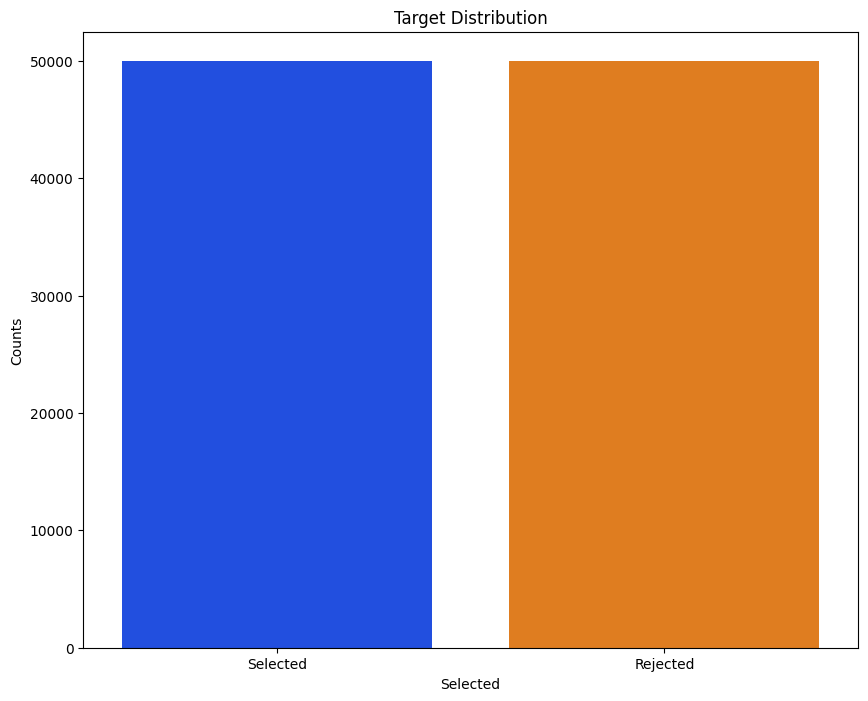

In [19]:
# Distribution of the Target Column

plt.figure(figsize=(10, 8))

sns.countplot(resume_df, x = "selected", palette="bright")
plt.title("Target Distribution")
plt.xlabel("Selected")
plt.ylabel("Counts")


- How do ats_score, interview_score, and technical_test_score compare between Selected and Rejected candidates

__Solution__
- From boxplot, selected candidates tend to have higher scores than rejected candidates

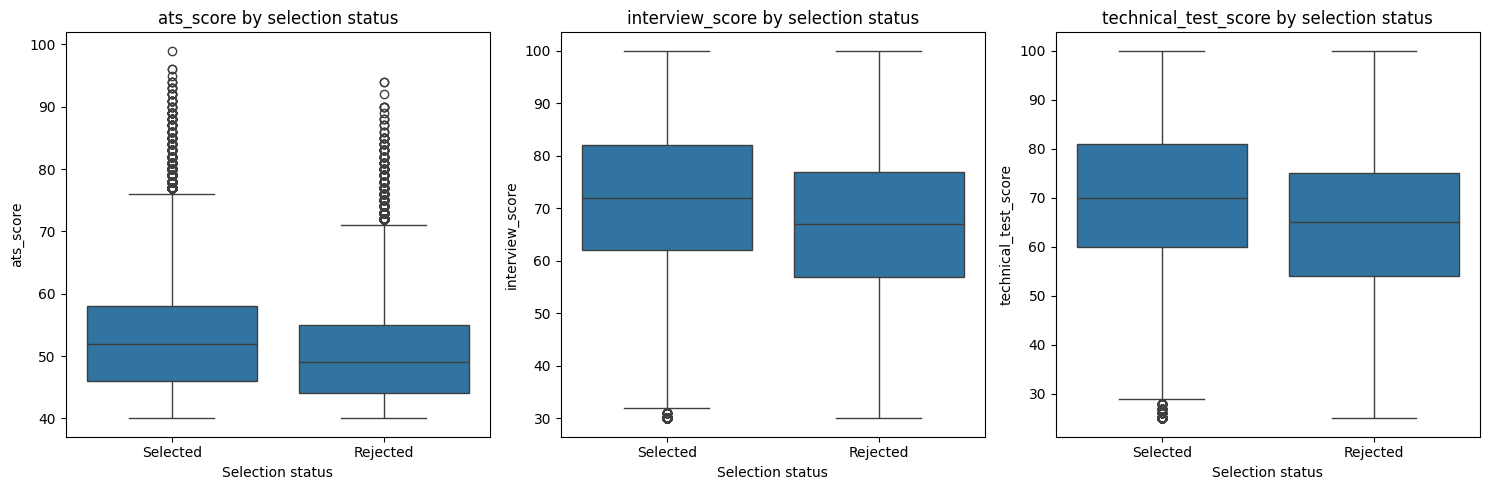

In [20]:
scores_col = ["ats_score", "interview_score", "technical_test_score"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, scores_col):
    sns.boxplot(resume_df, x = "selected", y = col, ax = ax)
    ax.set_title(f"{col} by selection status")
    ax.set_xlabel("Selection status")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

- How does the selection rate change across highest_education levels (bar chart)?

__Solution__
- Selection rate is roughly equal with Masters registering lowest selection

/tmp/ipykernel_58/3326975154.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(selection_rate, x = "highest_education", y = "selection_rate", palette="bright")


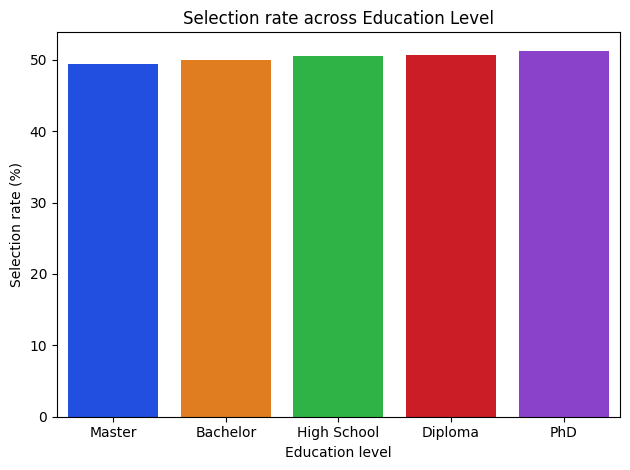

In [21]:
# Calculate selection rate

selection_rate = (resume_df.groupby("highest_education")["selected"]
                          .apply(lambda x: (x == "Selected").mean() * 100)
                          .reset_index(name = "selection_rate")
)

# Sort selection rate from lowest to highest

selection_rate = selection_rate.sort_values("selection_rate")

# Plot

plt.Figure(figsize=(10, 8))

sns.barplot(selection_rate, x = "highest_education", y = "selection_rate", palette="bright")
plt.title("Selection rate across Education Level")
plt.xlabel("Education level")
plt.ylabel("Selection rate (%)")
plt.tight_layout()
plt.show()

- How does the selection rate change across job_role (bar chart)? Are some roles more competitive than others?

__Solution__
- Selection rate across different Job Roles is roughly equal with UI UX Designer registering slightly lower rate while Business Analyst records the highest rate.

/tmp/ipykernel_58/751774393.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(selection, x = "job_role", y = "selection", palette="bright")


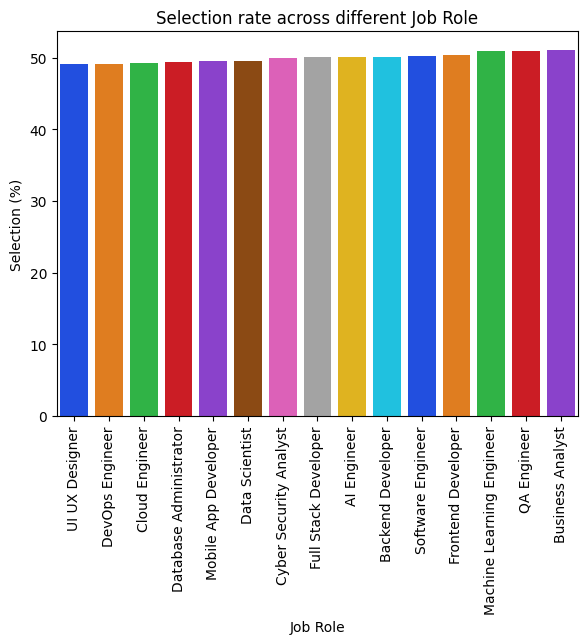

In [22]:
# Calculate selection rate

selection = (resume_df.groupby("job_role")["selected"]
                          .apply(lambda x: (x == "Selected").mean() * 100)
                          .reset_index(name = "selection")
)

# Sort selection from lowest to highest

selection = selection.sort_values("selection")

# Plot

plt.Figure(figsize=(10, 8))

sns.barplot(selection, x = "job_role", y = "selection", palette="bright")
plt.title("Selection rate across different Job Role")
plt.xlabel("Job Role")
plt.ylabel("Selection (%)")
plt.tight_layout()
plt.xticks(rotation=90)
plt.show()

- Do candidates with internship_experience or leadership_experience get selected at a noticeably higher rate?

__Solution__
- __Internship experience:__ Candidates without internship exeperience recorded higher selection than those with internship experience

- __Leadership experience:__ Candidates with leadership experience recoerded higher selection rate than those without.
With p-value of below 0.05, it means There is a statistically significant association with selection.

Intership Experience
  internship_experience  selection_rate
0                    No       54.093043
1                   Yes       44.961067

Leadership Experience
  leadership_experience  selection_rate
0                    No       44.165486
1                   Yes       57.354703


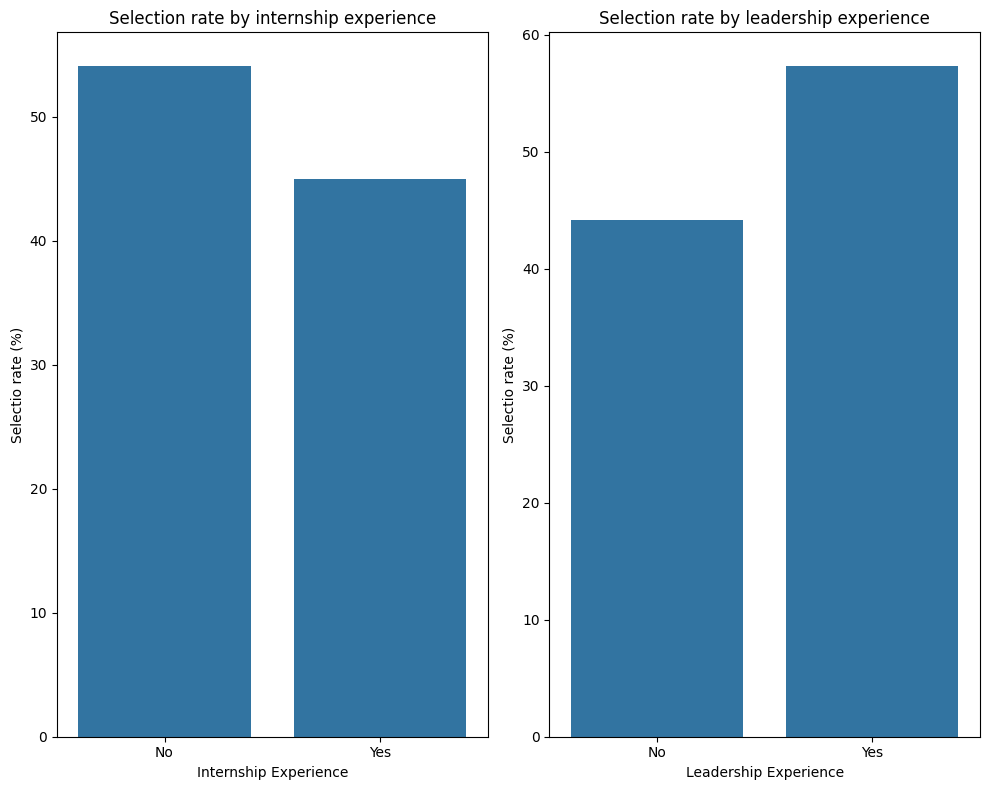


internship_experience
selected               Rejected  Selected
internship_experience                    
No                        25331     29848
Yes                       24669     20152
Chi2 Statistics 824.6174
P-Value 0.000000
Reject null hypothesis, There is a statistically significant association with selection

leadership_experience
selected               Rejected  Selected
leadership_experience                    
No                        31135     24628
Yes                       18865     25372
Chi2 Statistics 1715.9172
P-Value 0.000000
Reject null hypothesis, There is a statistically significant association with selection


In [23]:
# Calculate selection rate for intership_experience

internship_rate = (resume_df.groupby("internship_experience")["selected"]
                          .apply(lambda x: (x == "Selected").mean() * 100)
                          .reset_index(name = "selection_rate")
)

# Calculate selection rate for leadership_experience

leadership_rate = (resume_df.groupby("leadership_experience")["selected"]
                          .apply(lambda x: (x == "Selected").mean() * 100)
                          .reset_index(name = "selection_rate")
)

print("Intership Experience")
print(internship_rate)

print("\nLeadership Experience")
print(leadership_rate)

# Plotting both categorical variables

fig, axes = plt.subplots(1, 2, figsize=(10, 8))

sns.barplot(internship_rate, x = "internship_experience", y = "selection_rate", ax = axes[0])

axes[0].set_title("Selection rate by internship experience")
axes[0].set_xlabel("Internship Experience")
axes[0].set_ylabel("Selectio rate (%)")


sns.barplot(leadership_rate, x = "leadership_experience", y = "selection_rate", ax = axes[1])

axes[1].set_title("Selection rate by leadership experience")
axes[1].set_xlabel("Leadership Experience")
axes[1].set_ylabel("Selectio rate (%)")

plt.tight_layout()
plt.show()

# Test whether the differences are statistically significant

for col in ["internship_experience", "leadership_experience"]:

    h0 = "There is a statistically significant association with selection"
    h1 = "There is no statistically significant association with selection"

    alpha = 0.05

    contingency_table = pd.crosstab(resume_df[col], resume_df["selected"])

    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    print(f"\n{col}")
    print(contingency_table)
    print(f"Chi2 Statistics {chi2:.4f}")
    print(f"P-Value {p_value:4f}")

    if p_value < alpha:
        print(f"Reject null hypothesis, {h0}")
    else:
        print(f"Fail to reject null hypothesis, {h0}")

- Is there a relationship between your new technical_skills_count feature and selection?

__Solution__
- The selected candidates have higher mean compared to rejected in relation to technical skills count

In [24]:
# Compare the averages 

selected_skills = resume_df.loc[resume_df["selected"] == "Selected", "technical_skills_count"]

rejected_skills = resume_df.loc[resume_df["selected"] == "Rejected", "technical_skills_count"]

print("Selected candidates")
print(f"Mean: {selected_skills.mean():.2f}")

print("\nRejected candidates")
print(f"Mean: {rejected_skills.mean():.2f}")

# Statistical test

H0 = "The mean number of technical skills is the same for Selected and Rejected"
H1 = "The mean number of technical skills is not the same for Selected and Rejected"

alpha = 0.05

t_test, p_value = ttest_ind(selected_skills, rejected_skills, equal_var=False)

print(f"T-test: {t_test:.4f}")
print(f"P-value: {p_value:4f}")

if p_value < alpha:
    print(f"Reject null hypothesis, {H0}")
else:
    print(f"Fail to reject null hypothesis, {H0}")

Selected candidates
Mean: 6.61

Rejected candidates
Mean: 6.35
T-test: 17.5008
P-value: 0.000000
Reject null hypothesis, The mean number of technical skills is the same for Selected and Rejected


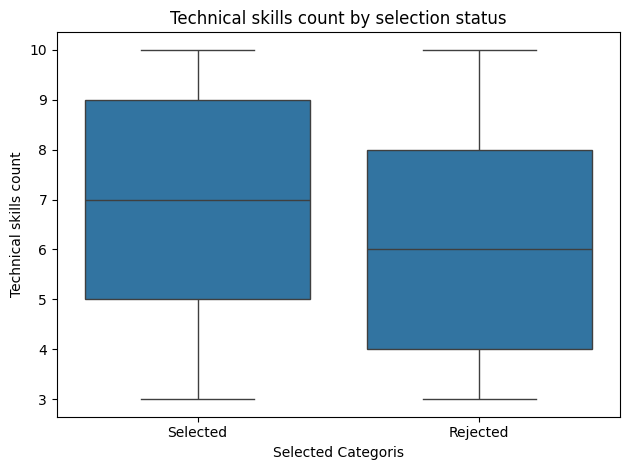

In [25]:
# Visualize the relationship

plt.Figure(figsize=(10, 8))

sns.boxplot(resume_df, x = "selected", y = "technical_skills_count")
plt.title("Technical skills count by selection status")
plt.xlabel("Selected Categoris")
plt.ylabel("Technical skills count")
plt.tight_layout()
plt.show()

- Is there a correlation heatmap pattern among the six score columns (communication_score, problem_solving_score, technical_test_score, interview_score, aptitude_score, resume_quality_score)? Do any move together strongly?

__Solution__
- There is no correlation among the six columns.

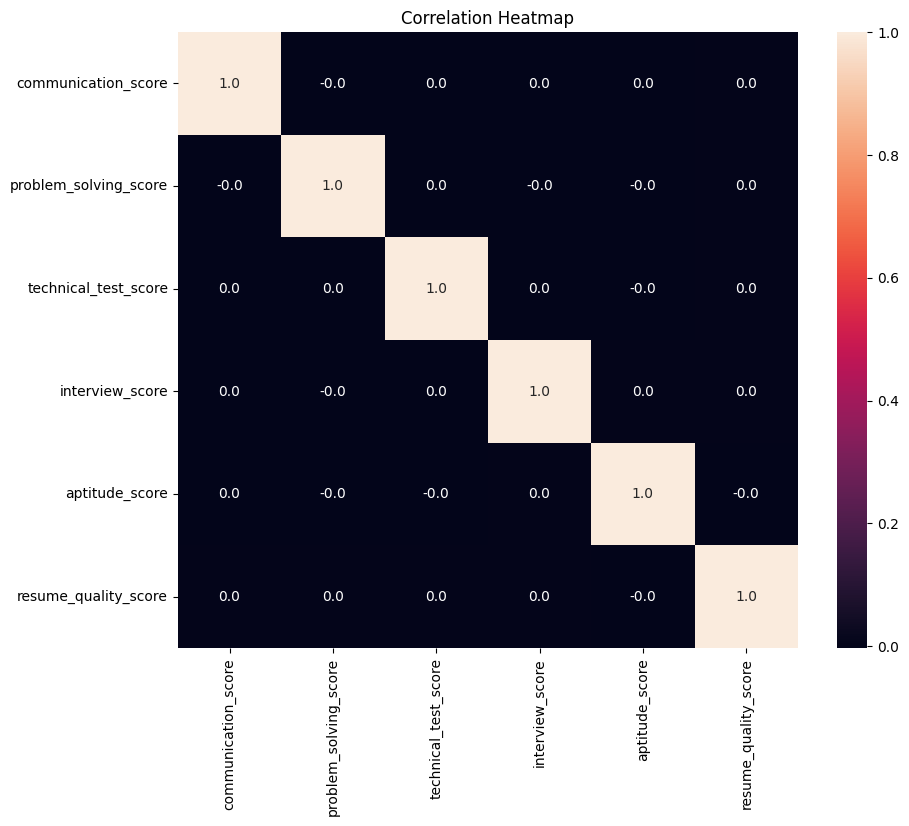

In [26]:
corr_columns = [
    "communication_score",
    "problem_solving_score",
    "technical_test_score",
    "interview_score",
    "aptitude_score",
    "resume_quality_score"
]

correlation = resume_df[corr_columns].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(correlation,annot=True, fmt=".1f")
plt.title("Correlation Heatmap")
plt.show()

- Which features seem most associated with being selected overall, and does that match your Step 4 hypothesis test results?

- Numerical features

__Solution__
- All features with significant at 0.05 which is true are the features seem most associated with beign selected overall.

In [27]:
ttest_results.sort_values("p_value")

,feature,selected group mean,rejected group mean,t-statistic,p_value,test used,significant_at_0.05
0,age,43.704840,32.280780,216.987936,0.000000e+00,independent ttest,True
1,cgpa,3.307416,3.189266,43.508456,0.000000e+00,independent ttest,True
2,graduation_year,2003.198520,2014.694500,-217.784283,0.000000e+00,independent ttest,True
3,experience_years,21.805080,10.306460,218.897850,0.000000e+00,independent ttest,True
15,ats_score,52.643600,49.834460,52.458941,0.000000e+00,independent ttest,True
11,expected_salary,212809.400000,141562.380000,200.435103,0.000000e+00,independent ttest,True
9,interview_score,71.796080,66.944680,53.072771,0.000000e+00,independent ttest,True
8,technical_test_score,70.043860,64.614200,55.451756,0.000000e+00,independent ttest,True
14,keyword_match_percentage,30.050258,26.133792,50.069007,0.000000e+00,independent ttest,True
22,previous_companies_count,2.492380,2.029460,42.966932,0.000000e+00,independent ttest,True


- Categorical

In [28]:
chi_results_df.sort_values("p_value")

,feature,type,test used,p_value,statistic,significant_at_0.05
7,leadership_experience,categorical,chisquare,0.000000e+00,1715.917172,True
5,current_job_title,categorical,chisquare,0.000000e+00,6026.502683,True
6,internship_experience,categorical,chisquare,2.398245e-181,824.617409,True
2,highest_education,categorical,chisquare,6.147998e-02,8.984822,False
8,job_role,categorical,chisquare,2.635542e-01,16.862963,False
0,country,categorical,chisquare,2.752384e-01,254.686213,False
11,availability,categorical,chisquare,4.099100e-01,3.971255,False
1,gender,categorical,chisquare,5.129630e-01,1.335103,False
10,remote_preference,categorical,chisquare,6.301158e-01,0.923703,False
4,field_of_study,categorical,chisquare,6.911306e-01,5.607252,False


### Split Features and Target, Then Train/Test Split

In [29]:
# Splitting Features

X = resume_df.drop(columns = [
    "selected", "country", "university", "field_of_study", 
    "resume_length", "certifications_count", "projects_completed", "publications"
])

y = resume_df["selected"]

# Numerical columns from X

num_columns = X.select_dtypes(include=["int", "float"]).columns.to_list()

# Categorical columns from X

cat_columns = X.select_dtypes(include=["object"]).columns.to_list()


# Split Train and Test set

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [30]:
print(y.unique())
print(y.value_counts())

['Selected' 'Rejected']
selected
Selected    50000
Rejected    50000
Name: count, dtype: int64


### Encode the Target(y)

In [31]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print(label_encoder.classes_)
print(y_train_encoded[:10])

['Rejected' 'Selected']
[0 0 0 1 0 1 0 1 0 1]


### Pipelines

In [32]:
# Numerical pipeline

num_pipeline = Pipeline(steps=[
                            ("imputer", SimpleImputer(strategy="median")),
                            ("scaler", StandardScaler())
                             
])

# Categorical pipeline

cat_pipeline = Pipeline(steps=[
                            ("imputer", SimpleImputer(strategy="most_frequent")),
                            ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


# Combine the pipelines

preprocessor = ColumnTransformer(transformers=[
    ("num", num_pipeline, num_columns),
    ("cat", cat_pipeline, cat_columns) 
])

### Define machine learning models

In [33]:
# Models

models = {
    "logistic_regression": LogisticRegression(max_iter=1000),
    "decision_tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "random_fr": RandomForestClassifier(n_estimators=500, max_depth=15, n_jobs=-1),
    "knn": KNeighborsClassifier(n_neighbors=7, metric="euclidean"),
    "gr_boosting": GradientBoostingClassifier(n_estimators=200, max_depth=5),
    "xgboost": XGBClassifier(n_estimators=200, random_state=42, eval_metric="logloss", max_depth=5, n_jobs=-1)
}

### Cross Validation

In [34]:
# 5-fold stratified cross-validation

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for model_name, model in models.items():

    print(f"\nStarting: {model_name}")
    
    pipeline = Pipeline(steps=[
                            ("preprocessor", preprocessor),
                            ("model", model)
    ])


    cv_scores = cross_validate(pipeline, X_train, y_train_encoded, cv = cv, scoring={
        "accuracy": "accuracy",
        "f1":"f1"
    }, n_jobs=-1, error_score="raise")

    print(f"Finished: {model_name}")


    results.append({
        "model": model_name,
        "mean cv accuracy": cv_scores["test_accuracy"].mean(),
        "mean cv f1": cv_scores["test_f1"].mean()
    })


Starting: logistic_regression
Finished: logistic_regression

Starting: decision_tree
Finished: decision_tree

Starting: random_fr
Finished: random_fr

Starting: knn
Finished: knn

Starting: gr_boosting
Finished: gr_boosting

Starting: xgboost
Finished: xgboost


### Comparison Table

In [35]:
comparison_table = pd.DataFrame(results)

comparison_table = comparison_table.sort_values(
    "mean cv f1",
    ascending=False
).reset_index(drop=True)

comparison_table

,model,mean cv accuracy,mean cv f1
0,gr_boosting,0.844750,0.849496
1,random_fr,0.833100,0.844955
2,xgboost,0.838862,0.843612
3,decision_tree,0.812813,0.828404
4,logistic_regression,0.813762,0.814890
5,knn,0.801775,0.807155


In [36]:
# print(f"{model_name}")
# print(f"f1_scores {cv_scores}")

### Hyperparameter Tuning

In [43]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42, n_jobs=-1))
])

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42))
])



### RandomForest RandomizedSearchCV.

In [48]:
# X_train_processed = preprocessor.fit_transform(X_train)

# print(X_train_processed.shape)

# print(X_train.shape)


In [44]:
rf_param_dist = {
    "model__n_estimators": [100, 150, 200, 250],
    "model__max_depth": [5, 10, 15, 20, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

rf_random = RandomizedSearchCV(
    estimator = rf_pipeline,
    param_distributions = rf_param_dist,
    n_iter = 10, 
    scoring = "f1",
    cv = 3,
    n_jobs = -1,
    random_state = 42,
    verbose = 2
)

rf_random.fit(X_train, y_train_encoded)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['age',
                                                                                'cgpa',
                                                                                'graduation_year',
                                                                                'experience_years',
                                                                                'communication_score',
                                                                                'problem_solving_score',
                                                                                'technical_test_score',
                                                                                'interview_score',
                                                                                'aptitude_score'...
                                                                                'remote_preference',
                                                                                'availability'])])),
                                             ('model',
                                              RandomForestClassifier(n_jobs=-1,
                                                                     random_state=42))]),
                   n_jobs=-1,
                   param_distributions={'model__max_depth': [5, 10, 15, 20,
                                                             None],
                                        'model__max_features': ['sqrt', 'log2'],
                                        'model__min_samples_leaf': [1, 2, 4],
                                        'model__min_samples_split': [2, 5, 10],
                                        'model__n_estimators': [100, 150, 200,
                                                                250]},
                   random_state=42, scoring='f1', verbose=2)

### Inspect the best parameters

In [49]:
print("Random Forest Parameters")
print(rf_random.best_params_)

print("\nBest Random Forest CV f1")
print(rf_random.best_score_)

Random Forest Parameters
{'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 20}

Best Random Forest CV f1
0.8461509434024354


### GradientBoosting RandomizedSearchCV

In [50]:
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(random_state = 42))
])

gb_param_dist = {
    "model__n_estimators": [100, 150, 200, 250],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [2, 3, 5, 7],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

gb_random = RandomizedSearchCV(
    estimator = gb_pipeline,
    param_distributions = gb_param_dist,
    n_iter = 10,
    cv = 3,
    scoring = "f1",
    n_jobs = -1,
    random_state = 42,
    verbose = 3
)

gb_random.fit(X_train, y_train_encoded)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['age',
                                                                                'cgpa',
                                                                                'graduation_year',
                                                                                'experience_years',
                                                                                'communication_score',
                                                                                'problem_solving_score',
                                                                                'technical_test_score',
                                                                                'interview_score',
                                                                                'aptitude_score'...
                                                                                'employment_type',
                                                                                'remote_preference',
                                                                                'availability'])])),
                                             ('model',
                                              GradientBoostingClassifier(random_state=42))]),
                   n_jobs=-1,
                   param_distributions={'model__learning_rate': [0.01, 0.05,
                                                                 0.1],
                                        'model__max_depth': [2, 3, 5, 7],
                                        'model__min_samples_leaf': [1, 2, 4],
                                        'model__min_samples_split': [2, 5, 10],
                                        'model__n_estimators': [100, 150, 200,
                                                                250]},
                   random_state=42, scoring='f1', verbose=3)

[CV 3/3] END model__learning_rate=0.1, model__max_depth=7, model__min_samples_leaf=4, model__min_samples_split=5, model__n_estimators=100;, score=0.848 total time= 1.2min
[CV 1/3] END model__learning_rate=0.05, model__max_depth=3, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=100;, score=0.849 total time=  33.2s
[CV 2/3] END model__learning_rate=0.05, model__max_depth=3, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=100;, score=0.847 total time=  34.6s
[CV 1/3] END model__learning_rate=0.01, model__max_depth=2, model__min_samples_leaf=4, model__min_samples_split=5, model__n_estimators=200;, score=0.821 total time=  48.9s
[CV 3/3] END model__learning_rate=0.01, model__max_depth=2, model__min_samples_leaf=4, model__min_samples_split=5, model__n_estimators=200;, score=0.822 total time=  45.4s
[CV 1/3] END model__learning_rate=0.05, model__max_depth=7, model__min_samples_leaf=2, model__min_samples_split=10, model__n_estimators=250;,

### Inspect best parameters

In [52]:
print("Best Parameters")
print(gb_random.best_params_)

print("\nBest cv_f1")
print(gb_random.best_score_)

Best Parameters
{'model__n_estimators': 250, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_depth': 3, 'model__learning_rate': 0.05}

Best cv_f1
0.8512812047489643


In [60]:
print(rf_random.best_score_)
print(gb_random.best_score_)

0.8461509434024354
0.8512812047489643


### Training the final Model

    - GradientBoosting Training

In [53]:
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42))
])

gb_pipeline.fit(X_train, y_train_encoded)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'cgpa',
                                                   'graduation_year',
                                                   'experience_years',
                                                   'communication_score',
                                                   'problem_solving_score',
                                                   'technical_test_score',
                                                   'interview_score',
                                                   'aptitude_score',
                                                   'expected_salary',
                                                   'resume_quality...
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender',
                                                   'highest_education',
                                                   'current_job_title',
                                                   'internship_experience',
                                                   'leadership_experience',
                                                   'job_role',
                                                   'employment_type',
                                                   'remote_preference',
                                                   'availability'])])),
                ('model', GradientBoostingClassifier(random_state=42))])

### Make predictions and Evaluate the model

In [56]:
y_pred = gb_pipeline.predict(X_test)

print("Classification report\n", classification_report(y_test_encoded, y_pred, target_names=label_encoder.classes_))

Classification report
               precision    recall  f1-score   support

    Rejected       0.87      0.80      0.84     10000
    Selected       0.82      0.88      0.85     10000

    accuracy                           0.84     20000
   macro avg       0.84      0.84      0.84     20000
weighted avg       0.84      0.84      0.84     20000



### Confusion Matrix

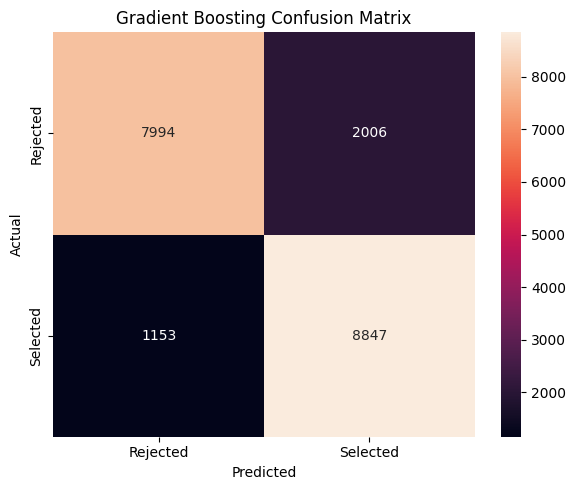

In [66]:
cm = confusion_matrix(y_test_encoded, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Rejected", "Selected"],
    yticklabels=["Rejected", "Selected"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Gradient Boosting Confusion Matrix")
plt.tight_layout()
plt.show()
